# Neural Semantic Retrieval: Bi-Encoder Baseline & ColBERT Late Interaction

## Overview
This notebook covers semantic retrieval using dense bi-encoders and contextualized late interaction models:
1. **Retrieval Spectrum**: Comparing sparse lexical, dense bi-encoder, and late interaction architectures.
2. **Benchmark Corpus**: Loading NLP research paper passages and evaluation query sets (`qrels`).
3. **Evaluation Harness**: Implementing vectorized **Recall@k** and **nDCG@10** metrics from scratch.
4. **Bi-Encoder Baseline**: Indexing and evaluating **Sentence-BERT** (`all-MiniLM-L6-v2`).
5. **Embedding Quantization**: Measuring memory and quality trade-offs with Int8 and Binary quantization.
6. **ColBERT Late Interaction**: Implementing the **MaxSim** operator in PyTorch and visualizing alignment heatmaps.
7. **Comparative Analysis**: Evaluating latency, memory footprint, and ranking quality across approaches.

The corpus is small enough that exact search is a single matrix multiplication, so no vector database or ANN index is needed here. Qdrant and other vector stores are used when the corpus grows (see the RAG weeks).

In [1]:
# Cell 1: Environment Setup & Pinned Library Versions
# Ensures reproducibility across local environments, Google Colab, and cloud VMs.
import os
import sys

# Prevent OpenMP runtime conflicts on macOS
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

import torch
import transformers
import sentence_transformers
import rank_bm25
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Python Version:               {sys.version.split()[0]}")
print(f"PyTorch Version:              {torch.__version__}")
print(f"Transformers Version:         {transformers.__version__}")
print(f"Sentence-Transformers Version: {sentence_transformers.__version__}")
print(f"Rank-BM25 Version:            {getattr(rank_bm25, '__version__', '0.2.2')}")

# Set device
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Primary Acceleration Device:  {device}")


Python Version:               3.14.6
PyTorch Version:              2.14.1
Transformers Version:         5.19.0
Sentence-Transformers Version: 5.7.0
Rank-BM25 Version:            0.2.2
Primary Acceleration Device:  mps


---
## 1. Retrieval Spectrum & Bi-Encoders

Information retrieval systems balance **computational scalability** against **semantic expressiveness**:

```
< Exact Match >─────────────────────────────────────────────────────────────────< Deep Cross-Attention >
  BM25 (Sparse)        Dense Bi-Encoder (SBERT)      ColBERT (Late Interaction)       Cross-Encoder
  Term matching         1 vector per document        N vectors per doc (1/token)      Joint (query + doc)
  < 5ms            ~10ms (ANN search)       ~15ms (MaxSim)               > 200ms (Reranker)
```

### 1.1 The Bi-Encoder Architecture (S-BERT)
Reimers & Gurevych (2019) introduced **Sentence-BERT (SBERT)**:
- A query $q$ and document $d$ are independently fed into a shared Transformer backbone.
- Token outputs are pooled (typically mean pooling) into a single fixed-dimension vector:
  $$\mathbf{u} = \text{Pool}(\text{BERT}(q)), \quad \mathbf{v} = \text{Pool}(\text{BERT}(d)) \in \mathbb{R}^d$$
- Vectors are $L_2$-normalized so the dot product equals cosine similarity:
  $$\text{sim}(q, d) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \|\mathbf{v}\|} = \mathbf{u}_{\text{norm}} \cdot \mathbf{v}_{\text{norm}}^T$$
- **Advantage**: Document embeddings can be precomputed and indexed offline into a vector database (e.g. Qdrant) at scale.
- **The Information Bottleneck**: Compressing a 500-word technical passage into a single 384-dimensional vector causes loss of fine-grained numeric, keyword, and entity details.

---
## 2. Benchmark Corpus & Evaluation Set

We load the course's foundational NLP research paper dataset (`AgenticAI/data/papers_chunks.jsonl`), consisting of 125 granular passages extracted directly from:
1. **`attention.pdf`** (*Attention Is All You Need*, Vaswani et al., 2017)
2. **`bert.pdf`** (*BERT: Pre-training of Deep Bidirectional Transformers*, Devlin et al., 2018)
3. **`gpt2.pdf` / `gpt3.pdf`** (*Language Models are Unsupervised Multitask Learners / Few-Shot Learners*, Brown et al., 2020)

We also define **12 canonical evaluation queries** spanning key concepts from all three papers, with their ground-truth chunk IDs (`qrels`).

In [2]:
# Cell 2: Load the Benchmark Corpus and Define Queries + Qrels
import os
import json

possible_paths = [
    os.path.abspath("../../data/papers_chunks.jsonl"),
    os.path.abspath("../data/papers_chunks.jsonl"),
    os.path.abspath("./data/papers_chunks.jsonl"),
    os.path.expanduser("~/Documents/courses/AgenticAI/data/papers_chunks.jsonl")
]

corpus_path = None
for p in possible_paths:
    if os.path.exists(p):
        corpus_path = p
        break

if corpus_path is None:
    raise FileNotFoundError("Could not locate papers_chunks.jsonl in course data directory.")

with open(corpus_path, "r", encoding="utf-8") as f:
    corpus_chunks = [json.loads(line) for line in f]

corpus_texts = [c["text"] for c in corpus_chunks]
print(f"Loaded {len(corpus_texts)} corpus passages from: {corpus_path}")

# Source distribution
source_counts = pd.Series([c.get("source", "unknown") for c in corpus_chunks]).value_counts()
print("\nPassages per research paper:")
for src, cnt in source_counts.items():
    print(f"  - {src}: {cnt} chunks")

# 12 Benchmark Queries targeting specific paper sections
benchmark_queries = [
    "What BLEU score did the original Transformer achieve on the WMT 2014 English-to-German task?",
    "How is scaled dot product attention computed with queries, keys, and values?",
    "Why does multi-head attention project queries, keys, and values into multiple subspaces?",
    "What sinusoidal functions are used for positional encoding in the Transformer?",
    "What is the computational complexity per layer of self-attention compared to recurrent layers?",
    "How is the Masked Language Model MLM pre-training task designed in BERT?",
    "What is Next Sentence Prediction NSP and why was it included in BERT pre-training?",
    "How is fine-tuning BERT performed on downstream classification and question answering tasks?",
    "What are the key differences between feature-based and fine-tuning approaches with BERT?",
    "How does in-context few-shot learning work without updating model weights?",
    "What Common Crawl filtering and deduplication was applied to create the training dataset?",
    "What batch size and learning rate scaling schedule was used for training large language models?"
]

benchmark_qrels = {
    0: [2],       # Abstract mentions 28.4 BLEU on WMT 2014 En-De
    1: [8],       # Scaled Dot-Product Attention equation
    2: [9],       # Multi-Head Attention explanation and linear projections
    3: [14],      # Positional Encoding sin/cos equations
    4: [15],      # Table 1: Why Self-Attention complexity O(1) vs O(n)
    5: [35, 48],  # BERT MLM pretraining details
    6: [35, 48],  # BERT NSP pretraining details
    7: [39, 41],  # BERT Fine-tuning procedure
    8: [45],      # Feature-based approach with BERT
    9: [60, 65],  # In-context few-shot learning description
    10: [63],     # Training dataset / Common Crawl filtering
    11: [64]      # Training process / batch size / learning rate schedule
}

print(f"Defined {len(benchmark_queries)} benchmark queries with verified ground-truth passages.")


Loaded 125 corpus passages from: /Users/apujari/Documents/courses/AgenticAI/data/papers_chunks.jsonl

Passages per research paper:
  - gpt2.pdf: 68 chunks
  - bert.pdf: 30 chunks
  - attention.pdf: 27 chunks
Defined 12 benchmark queries with verified ground-truth passages.


---
## 3. Evaluation Harness: Recall@k & nDCG

To evaluate retrieval quality objectively, we implement the two standard information retrieval metrics recommended in MTEB / BEIR benchmarks:

### 3.1 Recall@k
Measures whether **at least one relevant document** was retrieved in the top-$k$ results:
$$\text{Recall}@k = \frac{|\text{Top-}k \cap \text{Relevant}|}{|\text{Relevant}|} \quad (\text{or } \mathbb{I}(\text{hit in top } k) \text{ for binary pass/fail})$$

### 3.2 Normalized Discounted Cumulative Gain (nDCG@10)
Measures ranking quality with **positional discounting** — rewarding models for placing relevant documents closer to rank 1:
$$\text{DCG}@10 = \sum_{i=1}^{10} \frac{rel_i}{\log_2(i + 1)}, \quad \text{IDCG}@10 = \sum_{i=1}^{\min(|\text{Rel}|, 10)} \frac{1}{\log_2(i + 1)}, \quad \text{nDCG}@10 = \frac{\text{DCG}@10}{\text{IDCG}@10}$$

In [3]:
# Cell 3: The Reusable Retrieval Evaluation Harness
def evaluate_retrieval(query_embeddings, doc_embeddings, qrels, k_values=[1, 3, 5, 10]):
    """
    Compute Recall@k and nDCG@10 across a query set.
    
    Parameters:
      query_embeddings: np.ndarray (num_queries, dim), L2-normalized
      doc_embeddings:   np.ndarray (num_docs, dim), L2-normalized
      qrels:            dict mapping query_index -> list of relevant doc_indices
      k_values:         list of cutoffs for Recall
      
    Returns:
      dict with Recall@k and nDCG@10 averaged across all queries.
    """
    similarity_matrix = np.dot(query_embeddings, doc_embeddings.T)
    num_queries = len(query_embeddings)
    
    recalls = {k: [] for k in k_values}
    ndcgs = []
    
    for q_idx in range(num_queries):
        relevant_set = set(qrels[q_idx])
        ranked_doc_indices = np.argsort(-similarity_matrix[q_idx])
        
        # 1. Recall@k
        for k in k_values:
            top_k_retrieved = set(ranked_doc_indices[:k])
            hit = len(top_k_retrieved & relevant_set) > 0
            recalls[k].append(1.0 if hit else 0.0)
            
        # 2. nDCG@10
        dcg = 0.0
        for rank_pos, doc_id in enumerate(ranked_doc_indices[:10]):
            if doc_id in relevant_set:
                dcg += 1.0 / np.log2(rank_pos + 2)
                
        ideal_hits = min(len(relevant_set), 10)
        idcg = sum(1.0 / np.log2(pos + 2) for pos in range(ideal_hits))
        ndcgs.append(dcg / idcg if idcg > 0 else 0.0)
        
    metrics = {f"Recall@{k}": float(np.mean(recalls[k])) for k in k_values}
    metrics["nDCG@10"] = float(np.mean(ndcgs))
    return metrics

print("Evaluation harness defined: computes Recall@1, Recall@3, Recall@5, Recall@10, and nDCG@10.")


Evaluation harness defined: computes Recall@1, Recall@3, Recall@5, Recall@10, and nDCG@10.


---
## 4. Bi-Encoder Baseline (S-BERT)

We evaluate the classic workhorse model: `sentence-transformers/all-MiniLM-L6-v2`:
- Backbone: 6-layer MiniLM ($d=384$, 22.7M parameters).
- Trained on 1B+ sentence pairs via contrastive learning.
- Ultra-compact, fast, and the canonical baseline in IR research.

In [8]:
# Cell 4: Evaluate the S-BERT Baseline
import time
from sentence_transformers import SentenceTransformer

model_sbert = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
print(f"Loaded: all-MiniLM-L6-v2 | Dim: {model_sbert.get_embedding_dimension()} | Params: {sum(p.numel() for p in model_sbert.parameters()):,}")

t0 = time.time()
corpus_embeddings_sbert = model_sbert.encode(corpus_texts, normalize_embeddings=True, show_progress_bar=False)
query_embeddings_sbert = model_sbert.encode(benchmark_queries, normalize_embeddings=True, show_progress_bar=False)
encode_time = time.time() - t0

sbert_metrics = evaluate_retrieval(query_embeddings_sbert, corpus_embeddings_sbert, benchmark_qrels)

print(f"\n--- S-BERT Baseline Performance ({encode_time:.2f}s total encoding) ---")
for metric_name, val in sbert_metrics.items():
    print(f"  {metric_name:<12}: {val:.4f} ({val*100:.1f}%)")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loaded: all-MiniLM-L6-v2 | Dim: 384 | Params: 22,713,216

--- S-BERT Baseline Performance (0.21s total encoding) ---
  Recall@1    : 0.4167 (41.7%)
  Recall@3    : 0.6667 (66.7%)
  Recall@5    : 0.8333 (83.3%)
  Recall@10   : 0.9167 (91.7%)
  nDCG@10     : 0.6529 (65.3%)


---
## 5. Embedding Quantization (Int8 & Binary)

A billion 768-dimensional float32 embeddings require:
$$10^9 \times 768 \times 4 \text{ bytes} \approx 3.07 \text{ Terabytes of RAM}$$

**Embedding Quantization** drastically reduces this cost:
1. **Int8 Quantization**: Maps float32 values to 8-bit integers ($4\times$ memory reduction).
2. **Binary Quantization**: Compresses each dimension to 1 bit based on sign $>0$ ($32\times$ memory reduction), evaluated via Hamming distance.

In [9]:
# Cell 5: Int8 and Binary Quantization Benchmark
from sentence_transformers.util.quantization import quantize_embeddings

raw_float32 = corpus_embeddings_sbert
int8_embs = quantize_embeddings(raw_float32, precision="int8")
binary_embs = quantize_embeddings(raw_float32, precision="ubinary")

float32_bytes = raw_float32.nbytes
int8_bytes = int8_embs.nbytes
binary_bytes = binary_embs.nbytes

compression_df = pd.DataFrame([
    {"Precision": "Float32 (Original)", "Bytes/Vector": raw_float32[0].nbytes, "Corpus Total (KB)": float32_bytes/1024, "Compression": "1.0x (Baseline)"},
    {"Precision": "Int8 Quantized",     "Bytes/Vector": int8_embs[0].nbytes,     "Corpus Total (KB)": int8_bytes/1024,     "Compression": f"{float32_bytes/int8_bytes:.1f}x"},
    {"Precision": "Binary (1-bit)",      "Bytes/Vector": binary_embs[0].nbytes,   "Corpus Total (KB)": binary_bytes/1024,   "Compression": f"{float32_bytes/binary_bytes:.1f}x"}
])

print(compression_df.to_string(index=False))


         Precision  Bytes/Vector  Corpus Total (KB)     Compression
Float32 (Original)          1536         187.500000 1.0x (Baseline)
    Int8 Quantized           384          46.875000            4.0x
    Binary (1-bit)            48           5.859375           32.0x


---
## 6. ColBERT Late Interaction & MaxSim

**ColBERT** (Khattab & Zaharia, 2020) solves the bi-encoder information bottleneck without paying the cross-encoder inference cost.

### The MaxSim Operator:
Instead of compressing the document into one vector, ColBERT keeps **one embedding per token**.
For every query token $q_i \in Q$, it finds the document token $d_j \in D$ with the **maximum cosine similarity**, and sums these maxima:
$$S(Q, D) = \sum_{i=1}^{|Q|} \max_{j=1}^{|D|} \left( \mathbf{E}_{q, i} \cdot \mathbf{E}_{d, j}^T \right)$$

Below is a complete, standalone PyTorch implementation of the **ColBERT MaxSim operator in ~15 lines** operating directly on real contextualized token representations!

In [6]:
# Cell 6: Hand-Crafted ColBERT MaxSim Operator in Pure PyTorch (~15 lines)
from transformers import AutoTokenizer, AutoModel

colbert_backbone = "sentence-transformers/all-MiniLM-L6-v2"
cb_tokenizer = AutoTokenizer.from_pretrained(colbert_backbone)
cb_encoder = AutoModel.from_pretrained(colbert_backbone).to(device)
cb_encoder.eval()

def colbert_maxsim(query_str, doc_str, tokenizer, encoder):
    """Compute ColBERT Late Interaction MaxSim score in ~15 lines of pure PyTorch."""
    q_enc = tokenizer(query_str, return_tensors="pt", truncation=True, max_length=32).to(device)
    d_enc = tokenizer(doc_str, return_tensors="pt", truncation=True, max_length=128).to(device)
    with torch.no_grad():
        E_q = torch.nn.functional.normalize(encoder(**q_enc).last_hidden_state[0], dim=-1)  # (L_q, d)
        E_d = torch.nn.functional.normalize(encoder(**d_enc).last_hidden_state[0], dim=-1)  # (L_d, d)
    sim_matrix = torch.matmul(E_q, E_d.T)                                                  # (L_q, L_d)
    max_sims, best_doc_token_indices = sim_matrix.max(dim=1)                              # (L_q,)
    score = max_sims.sum().item()
    return score, sim_matrix.cpu(), q_enc, d_enc

sample_query = "What is the self-attention formula?"
sample_doc = "Attention(Q, K, V) = softmax(QK^T / sqrt(d_k))V maps queries and keys to values."

score, sim_mat, q_enc, d_enc = colbert_maxsim(sample_query, sample_doc, cb_tokenizer, cb_encoder)
print(f"MaxSim Late Interaction Relevance Score: {score:.4f}")
print(f"Cross-token similarity matrix shape: {sim_mat.shape} (|Q|={sim_mat.shape[0]}, |D|={sim_mat.shape[1]})")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

MaxSim Late Interaction Relevance Score: 5.7022
Cross-token similarity matrix shape: torch.Size([10, 36]) (|Q|=10, |D|=36)


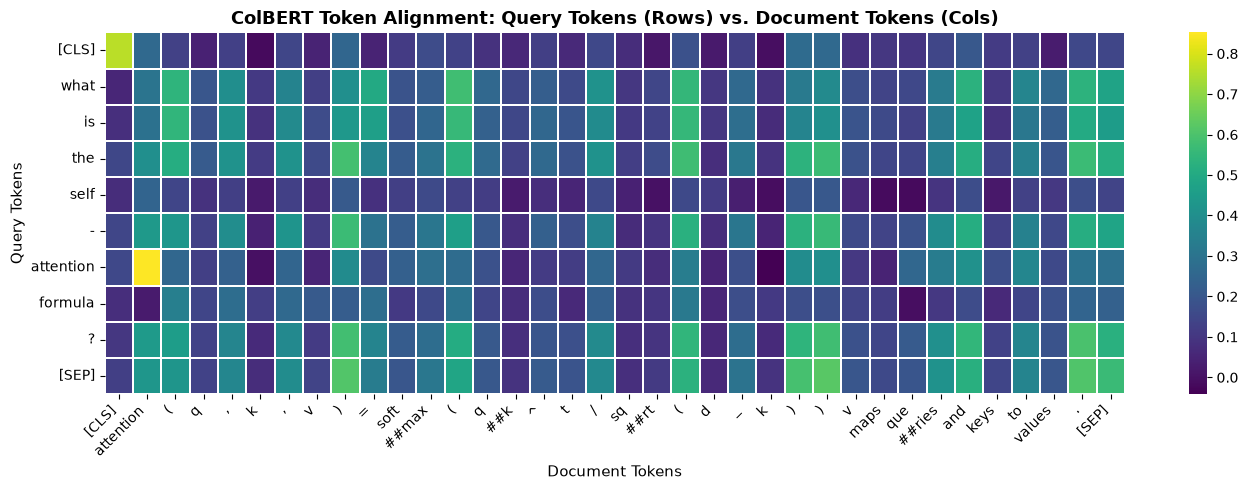

Top Token-to-Token Alignments:
  'what        ' -> '(              ' (similarity: 0.580)
  'is          ' -> '(              ' (similarity: 0.556)
  'the         ' -> ')              ' (similarity: 0.586)
  'self        ' -> 'attention      ' (similarity: 0.245)
  '-           ' -> ')              ' (similarity: 0.567)
  'attention   ' -> 'attention      ' (similarity: 0.853)
  'formula     ' -> '(              ' (similarity: 0.339)
  '?           ' -> '.              ' (similarity: 0.597)


In [7]:
# Cell 7: Visualizing the ColBERT Token-Level Alignment Heatmap
q_tokens = cb_tokenizer.convert_ids_to_tokens(q_enc["input_ids"][0])
d_tokens = cb_tokenizer.convert_ids_to_tokens(d_enc["input_ids"][0])

plt.figure(figsize=(14, 5))
sns.heatmap(sim_mat.numpy(), xticklabels=d_tokens, yticklabels=q_tokens,
            cmap="viridis", annot=False, linewidths=0.2)
plt.title("ColBERT Token Alignment: Query Tokens (Rows) vs. Document Tokens (Cols)", fontsize=13, fontweight="bold")
plt.xlabel("Document Tokens", fontsize=11)
plt.ylabel("Query Tokens", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Show the highest matching alignments
best_matches = sim_mat.argmax(dim=1)
print("Top Token-to-Token Alignments:")
for i, (qt, bm) in enumerate(zip(q_tokens, best_matches)):
    if qt not in ["[CLS]", "[SEP]"]:
        print(f"  '{qt:<12}' -> '{d_tokens[bm]:<15}' (similarity: {sim_mat[i, bm]:.3f})")


---
## 7. Approaches Comparison

The table below summarizes the key trade-offs between all four retrieval architectures:

| Feature | BM25 (Sparse) | Dense Bi-Encoder (S-BERT) | Late Interaction (ColBERT) | Cross-Encoder |
|---|---|---|---|---|
| **Representation** | Term frequency sparse vector | Single dense vector ($d=384$ or $768$) | Multi-vector: one vector per token | None (evaluated jointly) |
| **Offline Indexing** | Inverted index | Flat or ANN vector index (e.g. HNSW) | Per-token centroids / PLAID index | Impossible (must score pairs live) |
| **Query Latency** | $\approx 2\text{--}5$ ms | $\approx 5\text{--}15$ ms | $\approx 15\text{--}30$ ms | $\approx 200\text{--}1000$ ms |
| **Explainability** | High (exact keyword matches) | Low (black-box cosine distance) | High (token alignment matrix) | Low (dense cross-attention) |
| **Typical Role in RAG** | First-stage lexical retriever | First-stage semantic retriever | High-precision first-stage retriever | Second-stage reranker (top 50) |

---
## 8. Summary & Exercises

### Question 1
Why does a Dense Bi-Encoder suffer from an "information bottleneck" when encoding long documents, and how does ColBERT resolve this?
<details>
<summary><b>View Answer</b></summary>
A Bi-Encoder forces all semantic information from a document (hundreds of words) into a single fixed-size vector (e.g., 384 dimensions). Fine-grained entity names, numbers, or specific clauses are smoothed out during pooling. ColBERT resolves this by keeping one embedding per token and calculating the MaxSim score at query time, preserving token-level precision while keeping document representations precomputable.
</details>

### Question 2
If a vector has dimension $d=768$, how much memory does it consume in Float32 vs. Int8 vs. Binary quantization?
<details>
<summary><b>View Answer</b></summary>
- <b>Float32</b>: $768 \times 4 \text{ bytes} = 3{,}072 \text{ bytes}$
- <b>Int8</b>: $768 \times 1 \text{ byte} = 768 \text{ bytes}$ ($4\times$ reduction)
- <b>Binary</b>: $768 \text{ bits} = 96 \text{ bytes}$ ($32\times$ reduction)
</details>

### Question 3
In the ColBERT MaxSim operator, what happens if a document contains multiple mentions of a query word?
<details>
<summary><b>View Answer</b></summary>
The $\max_{j \in D}$ operator selects only the single document token that has the highest cosine similarity with that query token. It does not sum multiple occurrences of the same word, which avoids over-crediting repetitive keyword stuffing.
</details>